# Smoking Analysis

Sklearn can be very useful for data analysis in Python/Jupyter

## Information obtained from Kaggle

#### Project done by Miguel Estrada

In [1]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import pandas as pd
import sqlite3
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, roc_auc_score
import numpy as np
# Import SMOTE
from imblearn.over_sampling import SMOTE

#### SQL and CSV
Wanted to be able to read and write

In [3]:
# Read CSV
insurance_df = pd.read_csv('insurance.csv')

# Connect to SQLite database
conn = sqlite3.connect("data.db")

# Create SQL table from CSV
insurance_df.to_sql(
    "people",      # table name
    conn,
    if_exists="replace",
    index=False
)

# Read SQL table into DataFrame
insurance_df = pd.read_sql(
    "SELECT * FROM people",
    conn
)

conn.close()

In [4]:
insurance_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
insurance_df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [6]:
insurance_df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
insurance_df.region.value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

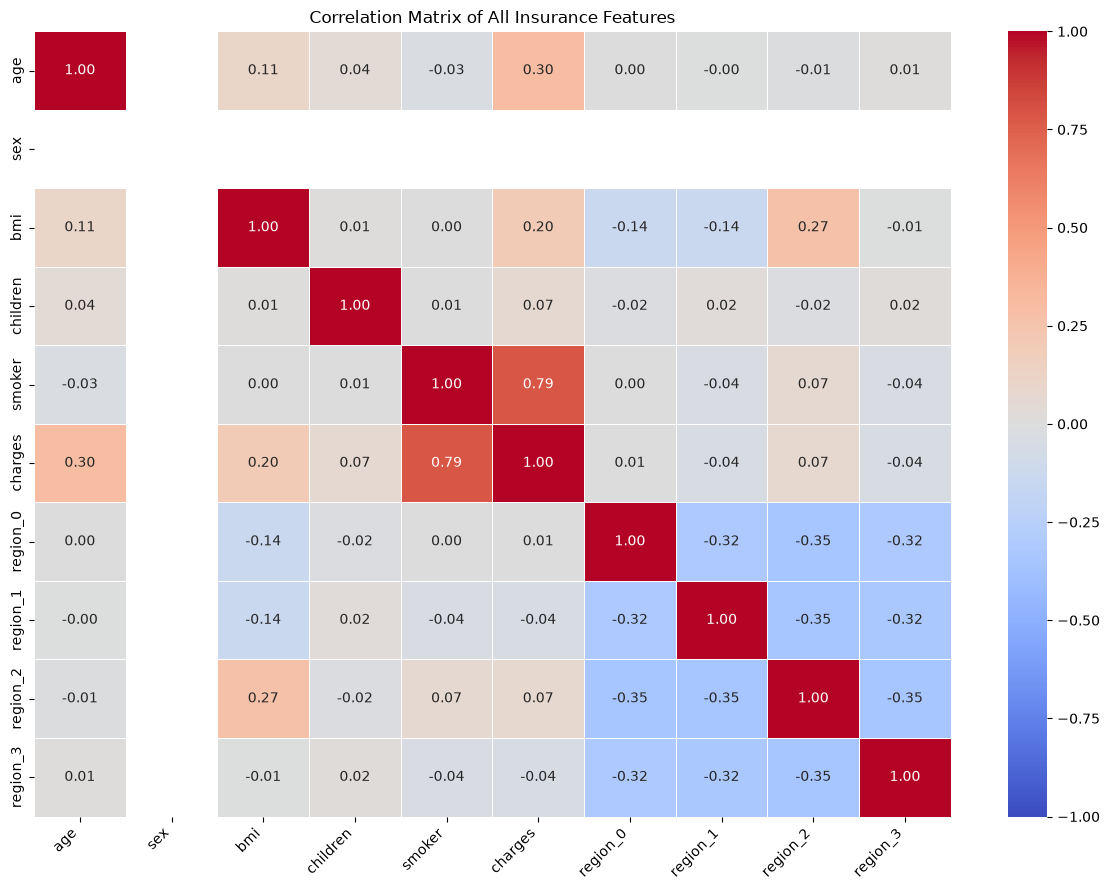

In [29]:
df_encoded = insurance_df.copy()
df_encoded['sex'] = df_encoded['sex'].map({'female': 0, 'male': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})
df_encoded = pd.get_dummies(df_encoded, columns=['region'], dtype=int)

# 3. Compute the full correlation matrix
corr_matrix = df_encoded.corr()

# 4. Plot the heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Correlation Matrix of All Insurance Features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Number of children per person')

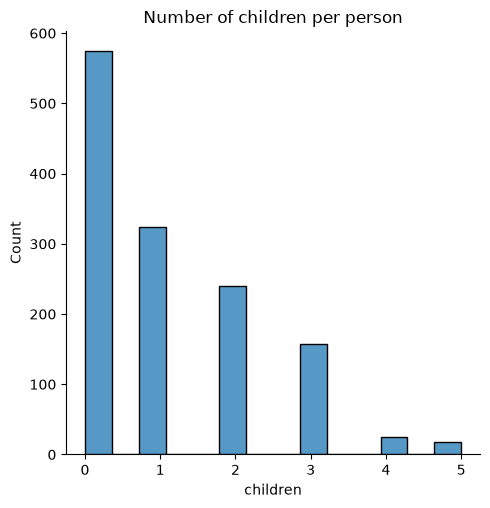

In [8]:
sns.displot(insurance_df['children'], kde=False)
plt.title("Number of children per person")

<Axes: xlabel='age', ylabel='children'>

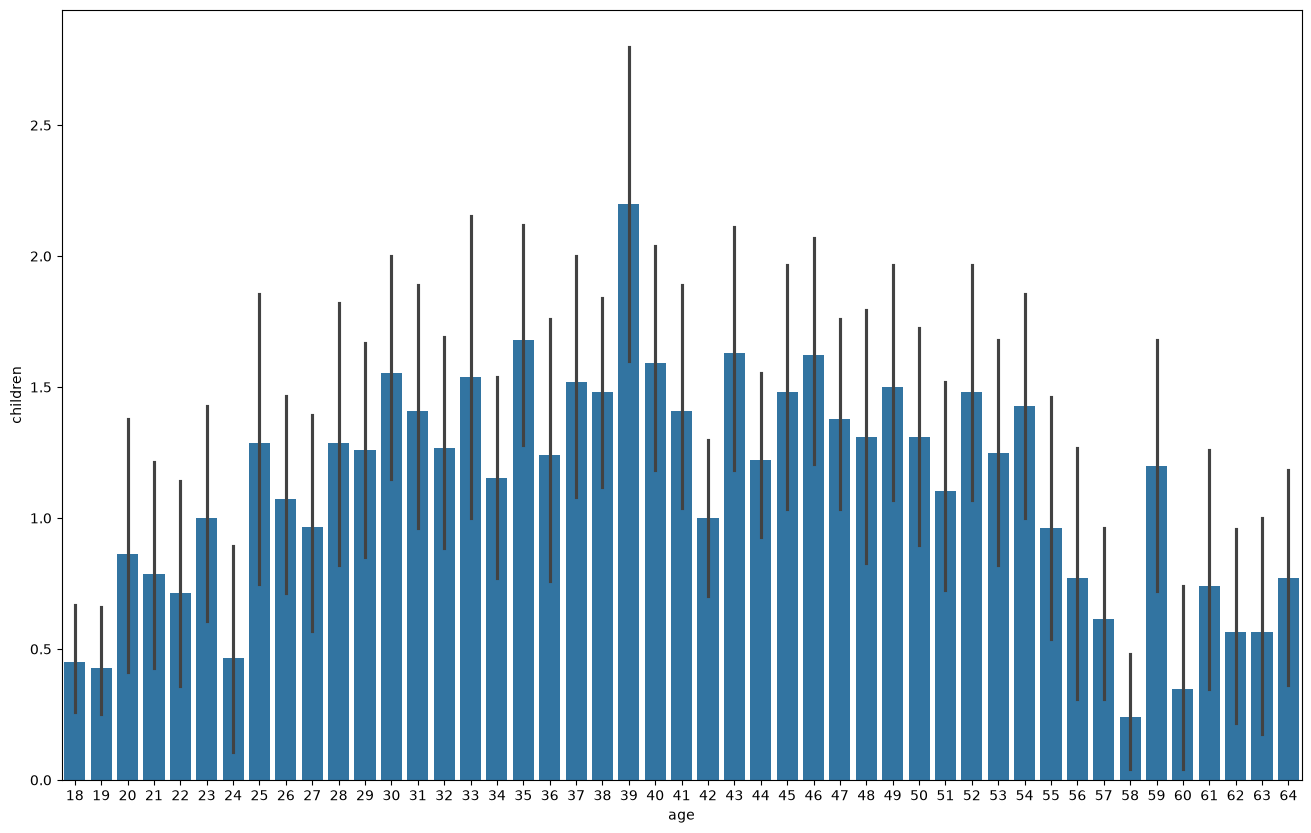

In [9]:
plt.figure(figsize=(16, 10))
sns.barplot(x=insurance_df['age'], y=insurance_df['children'])

#### Preparing data for Logistic Regression
Used for predicting if a person is a smoker or not based on their insurance and other data

In [10]:
X = insurance_df.drop('smoker', axis=1)
Y = insurance_df['smoker']

In [ ]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()

Y = np.array(Y)
Y = labelencoder.fit_transform(Y)

X.region = labelencoder.fit_transform(X.region.values)
X.sex = labelencoder.fit_transform(X.sex.values)

In [12]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.20)

In [13]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.fit_transform(x_test)

In [14]:
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

classifier = LogisticRegression()
classifier.fit(x_train_smote, y_train_smote)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [15]:
predictions = classifier.predict(x_test)

### Feature Importance & Selection
This section investigates which measurements contribute most to the Logistic Regression model.

In [21]:
# Keep the original column names for the importance results.
feature_names = X.columns

multiclass_roc_auc = make_scorer(
    roc_auc_score,
    multi_class='ovr',   # or 'ovo'
    average='macro',     # or 'weighted'
    response_method='predict_proba'
)

permutation_result = permutation_importance(
    classifier,
    x_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring=multiclass_roc_auc,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance Mean': permutation_result.importances_mean,
    'Importance Std': permutation_result.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by='Importance Mean',
    ascending=False
).reset_index(drop=True)

permutation_importance_df

,Feature,Importance Mean,Importance Std
0,charges,0.489853,0.033706
1,bmi,0.032244,0.007067
2,age,0.014865,0.003281
3,sex,0.001113,0.000462
4,children,0.000852,0.000597
5,region,0.000113,0.000119


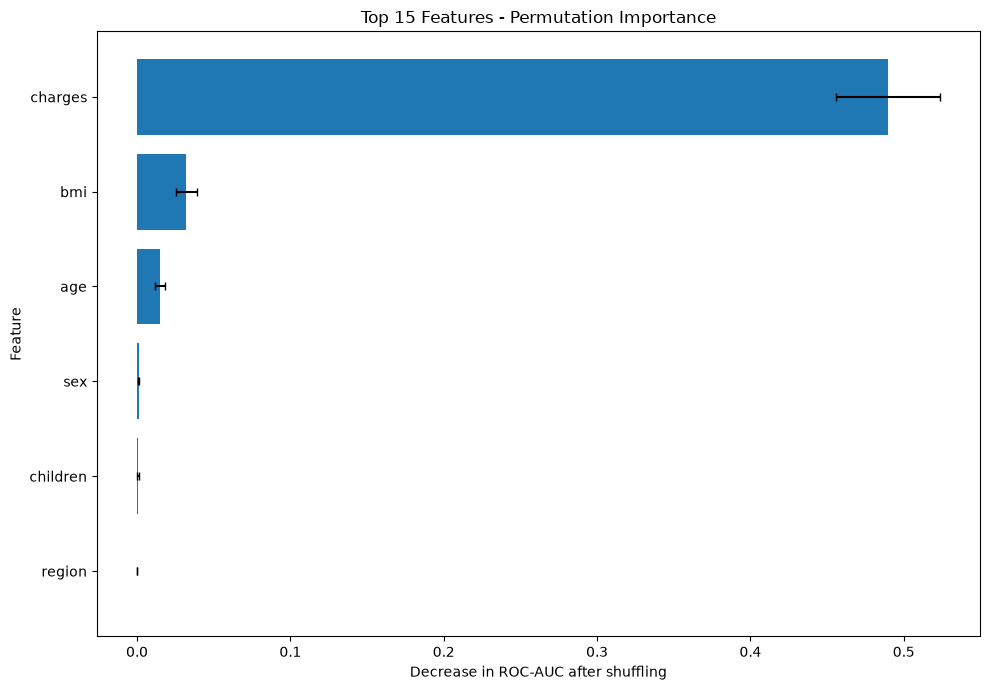

In [22]:
# Plot the 15 most important features.
top_features = permutation_importance_df.sort_values(
    by='Importance Mean',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance Mean'],
    xerr=top_features['Importance Std'],
    capsize=3
)
plt.xlabel('Decrease in ROC-AUC after shuffling')
plt.ylabel('Feature')
plt.title('Top 15 Features - Permutation Importance')
plt.tight_layout()
plt.show()

### Logistic Regression Coefficients

In [23]:
coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': classifier.coef_[0]
})

coefficient_df['Absolute Coefficient'] = coefficient_df['Coefficient'].abs()

coefficient_df = coefficient_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True)

coefficient_df

,Feature,Coefficient,Absolute Coefficient
0,charges,5.226555,5.226555
1,bmi,-2.209485,2.209485
2,age,-1.574958,1.574958
3,children,-0.471552,0.471552
4,sex,0.294005,0.294005
5,region,0.127681,0.127681


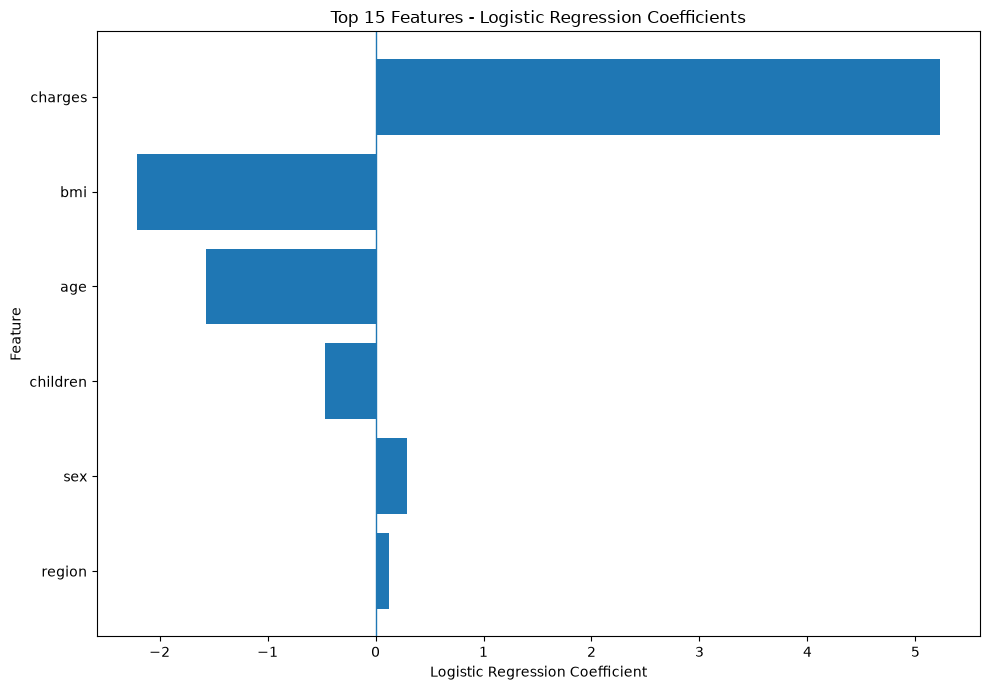

In [24]:
# Plot the 15 features with the largest absolute coefficients.
top_coefficients = coefficient_df.sort_values(
    by='Absolute Coefficient',
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_coefficients['Feature'],
    top_coefficients['Coefficient']
)
plt.axvline(x=0, linewidth=1)
plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.title('Top 15 Features - Logistic Regression Coefficients')
plt.tight_layout()
plt.show()

<Axes: >

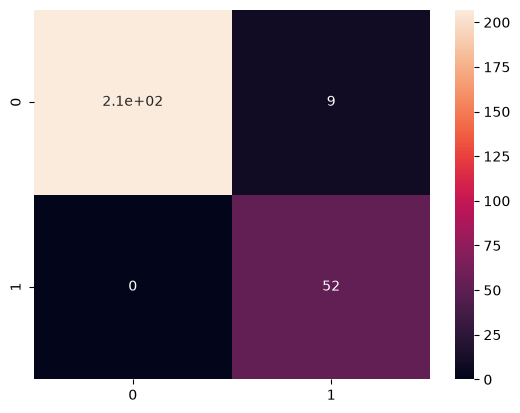

In [16]:
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True)

## There is a very big precision due to the correlation in the data

In [17]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98       216
           1       0.85      1.00      0.92        52

    accuracy                           0.97       268
   macro avg       0.93      0.98      0.95       268
weighted avg       0.97      0.97      0.97       268



In [18]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

mean_squared_error_ = mean_squared_error(y_test, predictions)
r2_score_ = r2_score(y_test, predictions)
mean_absolute_error_ = mean_absolute_error(y_test, predictions)

print("Mean Squared Error: {}".format(mean_squared_error_))
print("R2 score: {}".format(r2_score_))
print("Mean Absolute Error: {}".format(mean_absolute_error_))

Mean Squared Error: 0.033582089552238806
R2 score: 0.7852564102564104
Mean Absolute Error: 0.033582089552238806


In [19]:
## Accuracy of the model
accuracy_score(y_test, predictions)

0.9664179104477612